### Your name:

<pre> Shamir Alavi </pre>

### Collaborators:

<pre> None </pre>


In [1]:
import numpy as np
import pandas as pd

# to make this notebook's output stable across runs
np.random.seed(123)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


### Classification

Q1. Build a classification model for the default of credit card clients dataset. More info here:
https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients

- Explore the data
- Make sure you build a full data pipeline
- Do you require any data pre-processing? Are all the features useful? (Use only raw features)
- set the random seed to 123 (For splitting or any other random algorithm)
- Split data into training (80%) and testing (20%)
- Follow similar procedure as the one for week 2 (End-to-end Machine Learning Project). Remember apendix B
- Study the ROC Curve, decide threshold
- Use 2 classifiers.
    - Random Forest
        - tune only: n_estimators: {4, 5, 10, 20, 50} 
    - KNN Classfier 
        - tune only: n_neighbors: {3, 5, 10, 20} 
    - Which one performs better in the cross validation?
    
http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

- Cross-validation with 5-folds

- Other paramenters -> Use default

In [2]:
def plot_distribution(df, col, x_label):
    df[col].value_counts().sort_index().plot(
        kind="bar",
        xlabel=x_label,
        ylabel="Number of clients",
        title="Distribution of clients by " + x_label
    )
    plt.tight_layout()
    plt.show()

In [ ]:
### Your code here

## Feel free to use multiple cells

import os
import pandas as pd

DATA_PATH = os.path.join('..', 'data')

def load_credit_card_default_data(data_path=DATA_PATH):
    csv_path = os.path.join(data_path, "default_of_credit_card_clients.csv")
    return pd.read_csv(csv_path)

cc_original = load_credit_card_default_data()


In [ ]:
cc_original = cc_original.drop(cc_original.columns[0], axis=1)
cc_original.head()

In [4]:
cc_original.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='str')

In [6]:
# 1 = male; 2 = female
cc_original["SEX"].value_counts()   # imbalanced

SEX
2    18112
1    11888
Name: count, dtype: int64

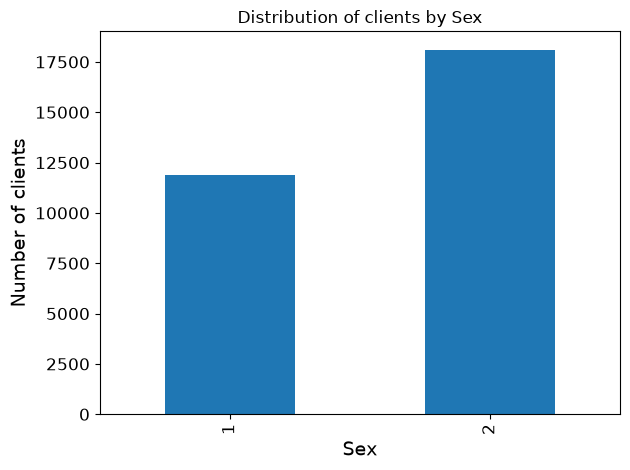

In [15]:
# split sex into categorcal values
cc_original["sex"] = pd.cut(cc_original["SEX"], bins=[-np.inf,1,np.inf], labels=[1,2])
plot_distribution(cc_original, "sex", "Sex")

In [6]:
# 1 = graduate school; 2 = university; 3 = high school; 4 = others
cc_original["EDUCATION"].value_counts()   # imbalanced

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [16]:
# consolidate other categories into category 4
cc_original["EDUCATION"] = cc_original["EDUCATION"].replace({
    0: 4,
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 4,
})

cc_original["EDUCATION"].value_counts()

EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

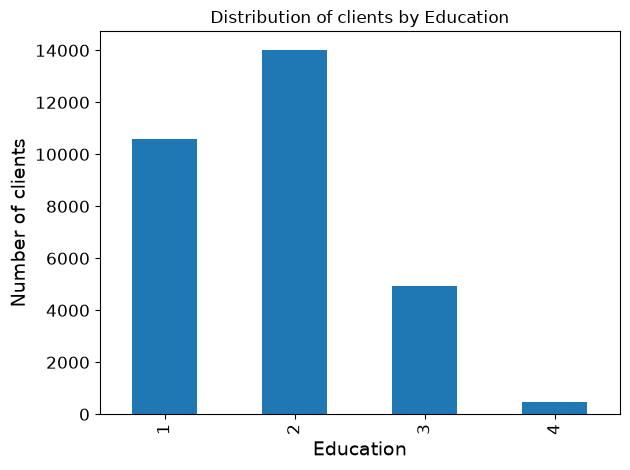

In [17]:
# split education into categorcal values
cc_original["education"] = pd.cut(cc_original["EDUCATION"], bins=[-np.inf,1,2,3,np.inf], labels=[1,2,3,4])
plot_distribution(cc_original, "education", "Education")

In [19]:
# 1 = married; 2 = single; 3 = others

cc_original["MARRIAGE"] = cc_original["MARRIAGE"].replace({
    0: 3,
    1: 1,
    2: 2,
    3: 3
})

cc_original["MARRIAGE"].value_counts()   # imbalanced

MARRIAGE
2    15964
1    13659
3      377
Name: count, dtype: int64

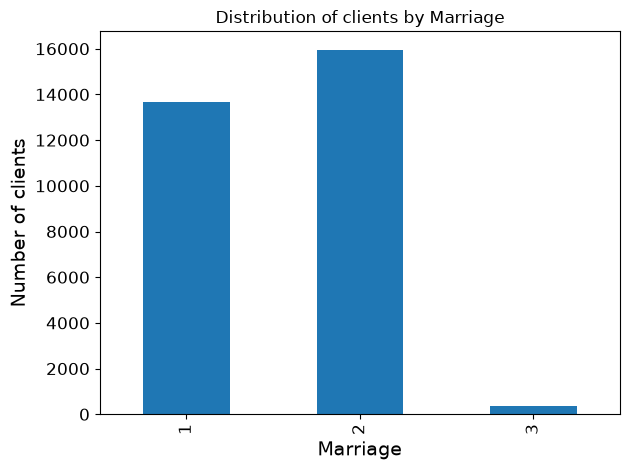

In [21]:
# split marriage into categorcal values
cc_original["marriage"] = pd.cut(cc_original["MARRIAGE"], bins=[-np.inf,1,2,np.inf], labels=[1,2,3])
plot_distribution(cc_original, "marriage", "Marriage")

In [ ]:
cc_original["AGE"].value_counts()   # imbalanced

In [14]:
cc_original["AGE"].describe()

count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

In [ ]:
cc_original["AGE"].hist(bins=10, figsize=(20,15))
# save_fig("attribute_histogram_plots")

plt.show()

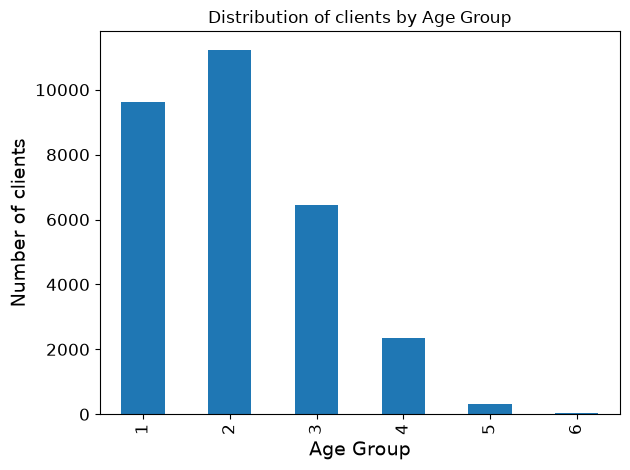

In [23]:
# split age into categorcal values
cc_original["age_group"] = pd.cut(cc_original["AGE"], bins=[-np.inf,29,39,49,59,69,np.inf], labels=[1,2,3,4,5,6])

plot_distribution(cc_original, "age_group", "Age Group")

In [24]:
cc_original.isna().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
sex                           0
education                     0
marriage                      0
age_group                     0
dtype: int64

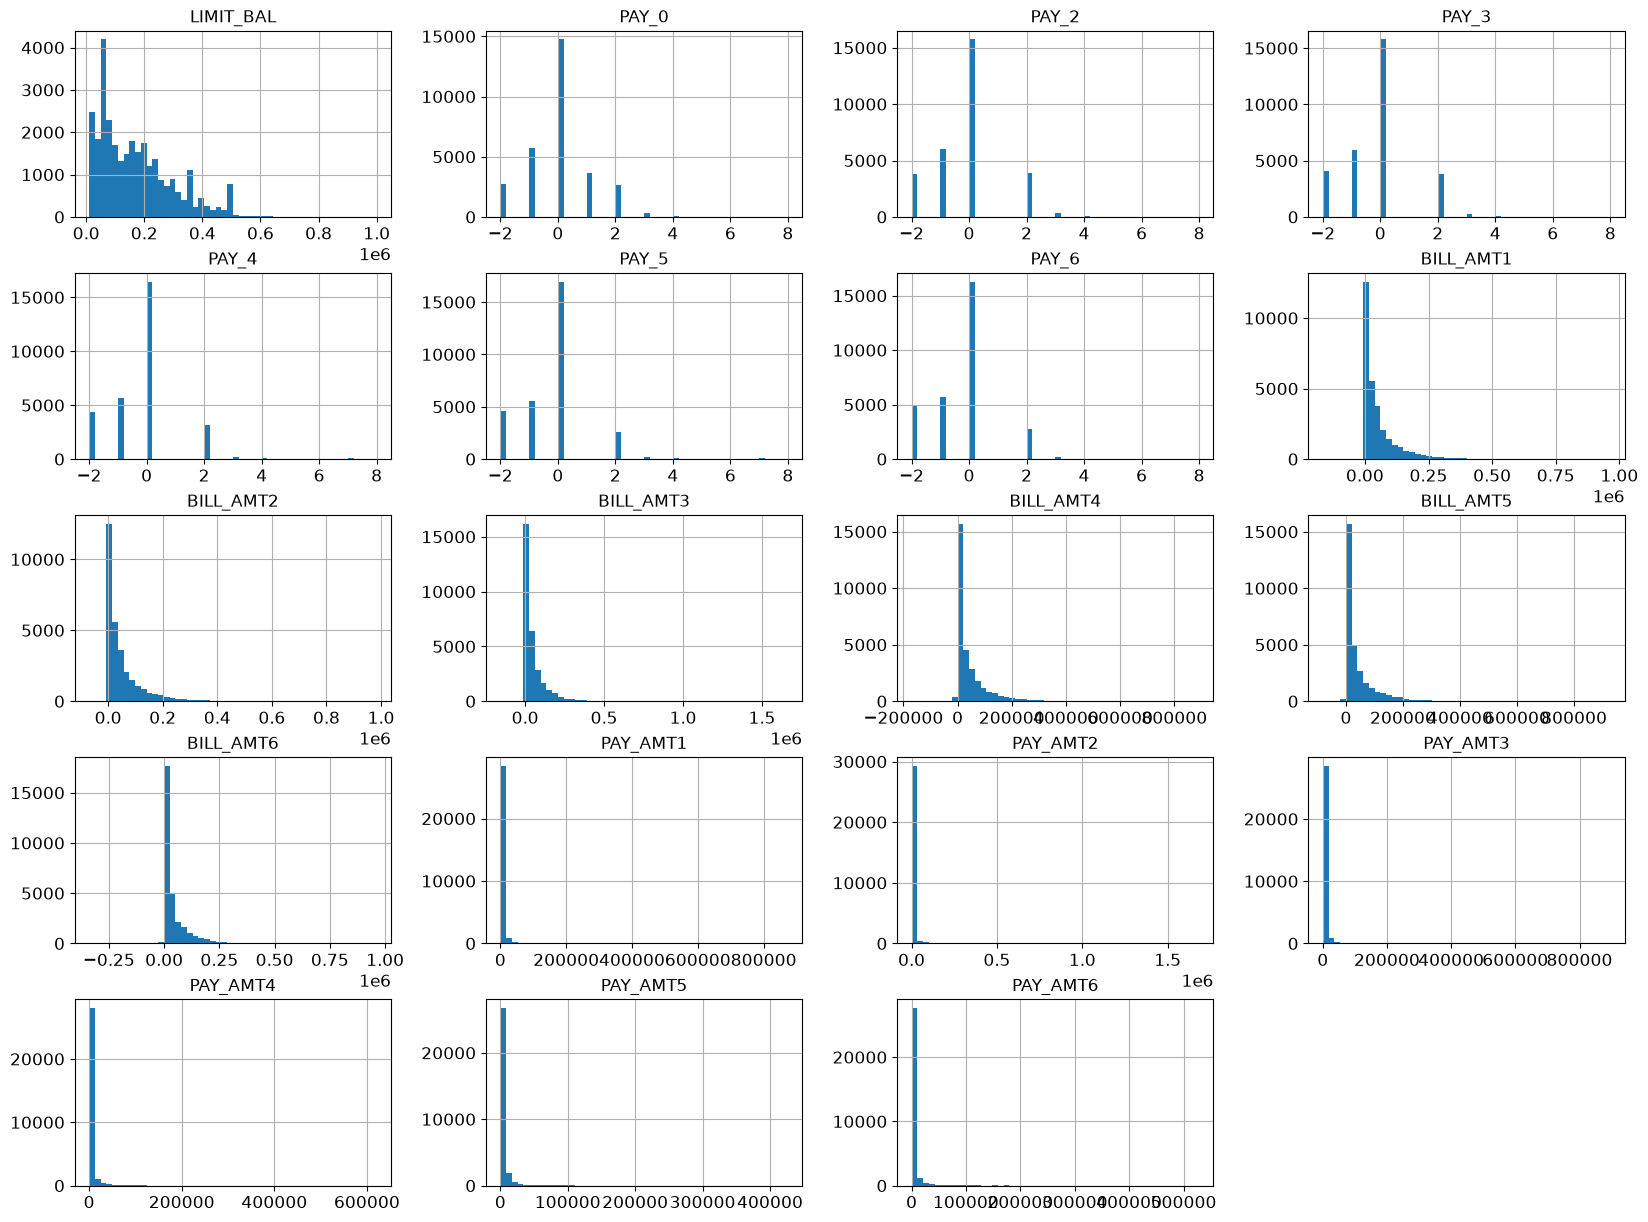

In [28]:
columns = [
    "LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
]

cc_original[columns].hist(bins=50, figsize=(20, 15))
plt.show()

In [25]:
cc_original.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month', 'sex', 'education', 'marriage',
       'age_group'],
      dtype='str')

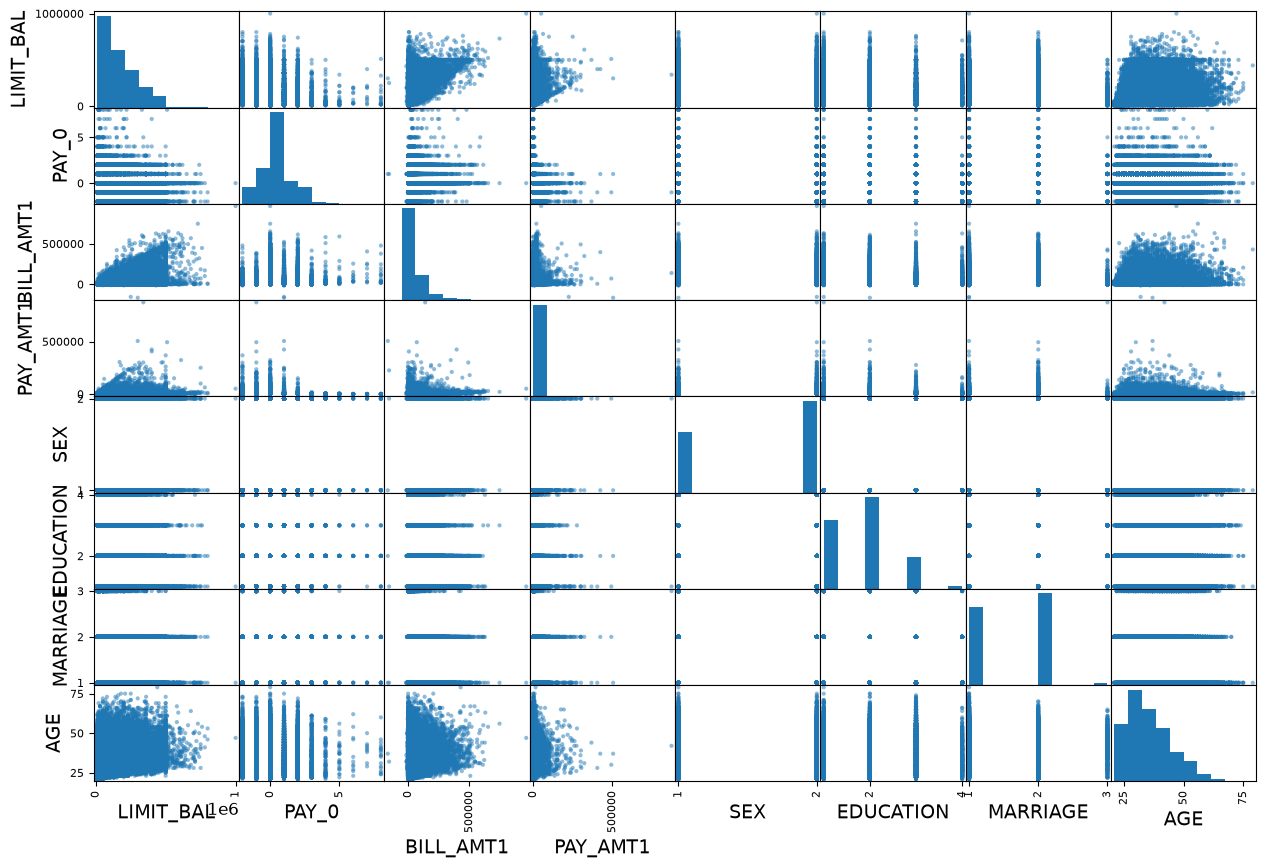

In [31]:
from pandas.plotting import scatter_matrix

attributes = ['LIMIT_BAL', 'PAY_0', 'BILL_AMT1', 'PAY_AMT1', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
scatter_matrix(cc_original[attributes], figsize=(15, 10))
plt.show()

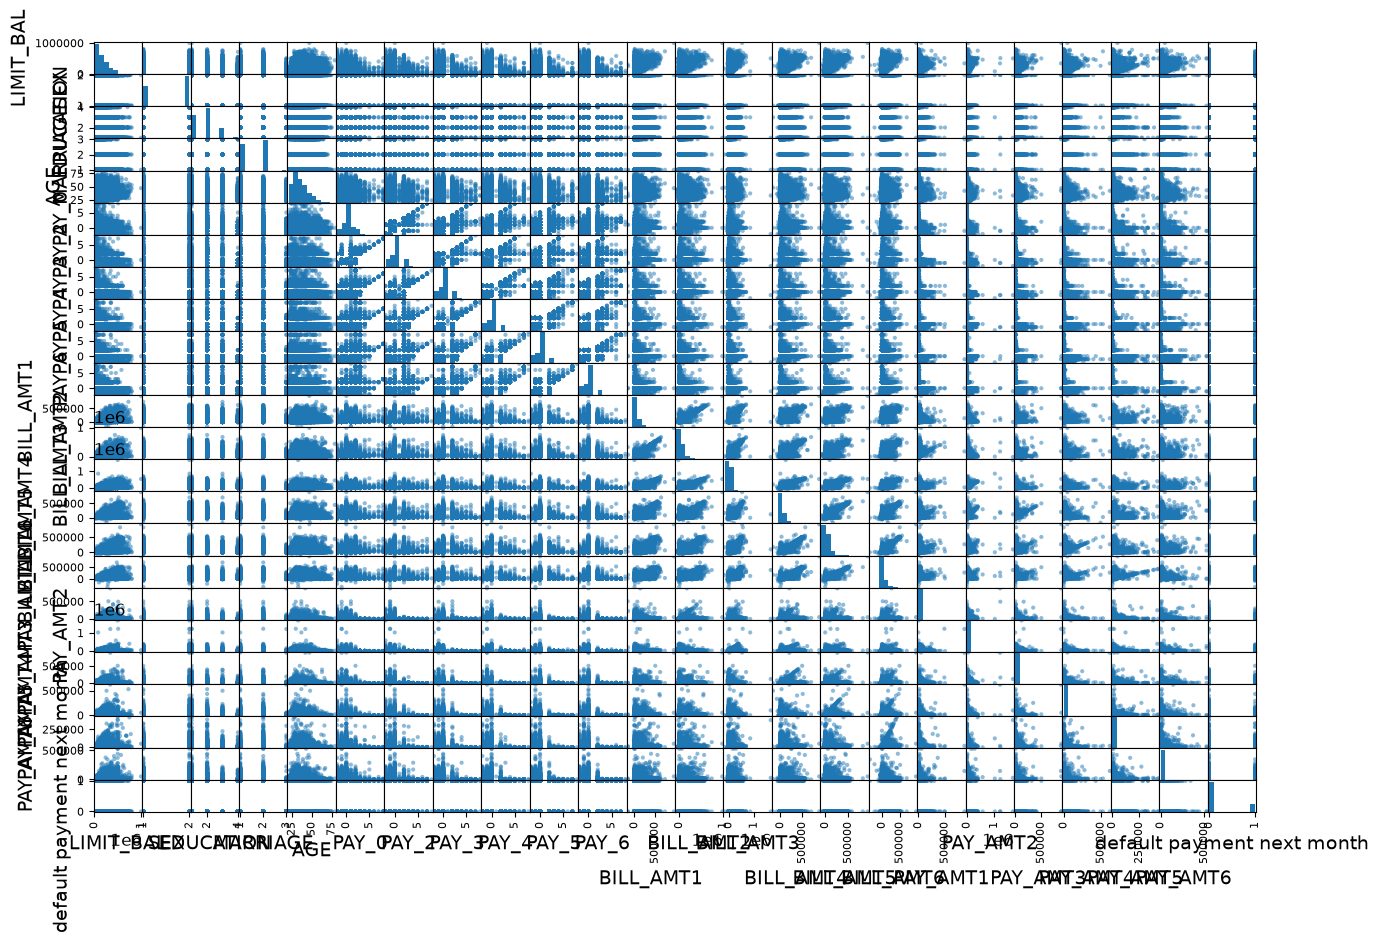

In [32]:
scatter_matrix(cc_original, figsize=(15, 10))
plt.show()

In [26]:
cc_original = cc_original.drop(columns=['ID', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE'])
cc_original.columns

Index(['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
       'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
       'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6', 'default payment next month', 'sex', 'education',
       'marriage', 'age_group'],
      dtype='str')

In [27]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=123)

for train_index, test_index in split.split(cc_original, cc_original["sex"]):
    strat_train_set_sex = cc_original.loc[train_index]
    strat_test_set_sex = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["education"]):
    strat_train_set_education = cc_original.loc[train_index]
    strat_test_set_education = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["marriage"]):
    strat_train_set_marriage = cc_original.loc[train_index]
    strat_test_set_marriage = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["age_group"]):
    strat_train_set_age_group = cc_original.loc[train_index]
    strat_test_set_age_group = cc_original.loc[test_index]

In [28]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder, PowerTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV


# Features
log_cols = [
    "LIMIT_BAL",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

standard_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    
]

cat_cols = [
    'sex',
    'education',
    'marriage',
    'age_group'
]


# Log transformation + scaling
log_pipeline = Pipeline([
    ("transform", PowerTransformer(method="yeo-johnson")),
    # ("log", FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)))),
    ("scale", StandardScaler())
])

# Full preprocessing pipeline for Random Forest
preprocessing_rf = ColumnTransformer([
    ("cat", OneHotEncoder(), cat_cols)
], remainder="passthrough")             # Pass numerical columns as-if to the model

# Full preprocessing pipeline for KNN
preprocessing_knn = ColumnTransformer([
    ("log", log_pipeline, log_cols),
    ("standard", StandardScaler(), standard_cols),
    ("cat", OneHotEncoder(), cat_cols)
])


# Full model pipeline
random_forest = Pipeline([
    ("preprocessing", preprocessing_rf),
    ("rf_classifier", RandomForestClassifier())
])

knn = Pipeline([
    ("preprocessing", preprocessing_knn),
    ("knn_classifier", KNeighborsClassifier())
])


# Grid search
param_grid_rf = {
    "rf_classifier__n_estimators": [4, 5, 10, 20, 50]
}

param_grid_knn = {
    "knn_classifier__n_neighbors": [3, 5, 10, 20]
}

grid_search_rf = GridSearchCV(
    random_forest,
    param_grid_rf,
    cv=5,
    scoring="roc_auc"
)

grid_search_knn = GridSearchCV(
    knn,
    param_grid_knn,
    cv=5,
    scoring="roc_auc"
)

In [30]:
def run_grid_search(strat_train_set, grid_search, model_name):
    start = time.time()

    grid_search.fit(
        strat_train_set.drop("default payment next month", axis=1),
        strat_train_set["default payment next month"]
    )

    end = time.time()

    print(f"Time taken: {end - start:.2f} seconds")
    print("Best parameters:", grid_search.best_params_)
    print(f"Best CV ROC-AUC {model_name}:", grid_search.best_score_)

    return grid_search

In [31]:
grid_search_rf_sex = run_grid_search(strat_train_set_sex, grid_search_rf, "Random Forest (stratified col: sex)")

Time taken: 35.36 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: sex): 0.7558934429673843


In [32]:
grid_search_rf_education = run_grid_search(strat_train_set_education, grid_search_rf, "Random Forest (stratified col:education )")

Time taken: 39.65 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col:education ): 0.754273451670842


In [33]:
grid_search_rf_marriage = run_grid_search(strat_train_set_marriage, grid_search_rf, "Random Forest (stratified col: marriage)")

Time taken: 37.67 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: marriage): 0.7546584067434597


In [34]:
grid_search_rf_age_group = run_grid_search(strat_train_set_age_group, grid_search_rf, "Random Forest (stratified col: age_group)")

Time taken: 38.94 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: age_group): 0.7576200968151339


In [35]:
grid_search_knn_sex = run_grid_search(strat_train_set_sex, grid_search_knn, "KNN (stratified col: sex)")

Time taken: 29.39 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: sex): 0.7495027770826588


In [36]:
grid_search_knn_education = run_grid_search(strat_train_set_education, grid_search_knn, "KNN (stratified col:education )")

Time taken: 31.47 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col:education ): 0.7479495578776605


In [37]:
grid_search_knn_marriage = run_grid_search(strat_train_set_marriage, grid_search_knn, "KNN (stratified col: marriage)")

Time taken: 30.53 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: marriage): 0.75036056757251


In [38]:
grid_search_knn_age_group = run_grid_search(strat_train_set_age_group, grid_search_knn, "KNN (stratified col: age_group)")

Time taken: 31.50 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: age_group): 0.751027526829908


### Check cross validation scores

In [40]:
results_rf = pd.DataFrame(grid_search_rf.cv_results_)

results_rf[
    [
        "param_rf_classifier__n_estimators",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values("mean_test_score", ascending=False).head(3)

,param_rf_classifier__n_estimators,mean_test_score,std_test_score
4,50,0.757620,0.008071
3,20,0.741825,0.007506
2,10,0.724515,0.008245


In [41]:
results_knn = pd.DataFrame(grid_search_knn.cv_results_)

results_knn[
    [
        "param_knn_classifier__n_neighbors",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values("mean_test_score", ascending=False).head(3)

,param_knn_classifier__n_neighbors,mean_test_score,std_test_score
3,20,0.751028,0.007445
2,10,0.736144,0.007113
1,5,0.705488,0.005123


## Decide ROC threshold using stratified cross validation

#### Generate out-of-fold probabilities

In [45]:
'''
Why pass grid_search_rf instead of grid_search_rf.best_estimator_?

Because grid_search_rf includes the hyperparameter search.
Passing it into cross_val_predict means each outer fold performs its own hyperparameter search using only that fold's training portion.
This avoids using information from the held-out fold during hyperparameter selection.

This is nested cross-validation, so it takes longer to run.
'''


from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Separate features and target
X_train = strat_train_set_age_group.drop(
    "default payment next month", axis=1
)

y_train = strat_train_set_age_group["default payment next month"]

# Define the outer cross-validation folds
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

# Generate out-of-fold probabilities
y_oof_prob = cross_val_predict(
    grid_search_rf,
    X_train,
    y_train,
    cv=outer_cv,
    method="predict_proba"
)[:, 1]

#### Calculate Youden's J

In [43]:
from sklearn.metrics import roc_curve

# Calculate ROC curve using out-of-fold probabilities
fpr, tpr, thresholds = roc_curve(y_train, y_oof_prob)

# Calculate Youden's J
j_scores = tpr - fpr

# Find the threshold with the highest J
best_index = np.argmax(j_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)
print("Best Youden's J:", j_scores[best_index])

Best threshold: 0.27099999999999996
Best Youden's J: 0.390207773583355


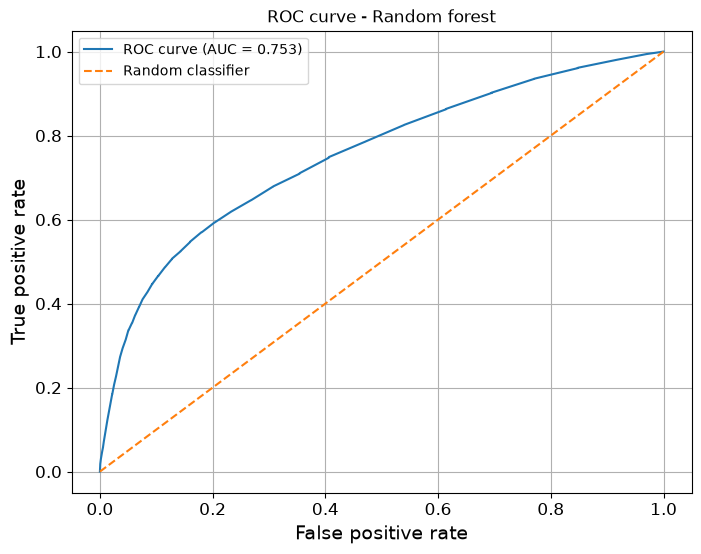

In [50]:
from sklearn.metrics import auc

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve - Random forest")
plt.legend()
plt.grid(True)

plt.show()

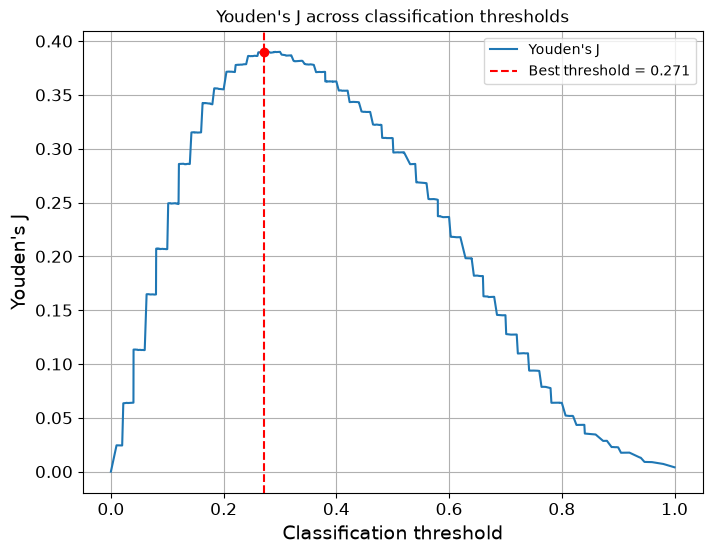

In [48]:
plt.figure(figsize=(8, 6))

plt.plot(thresholds, j_scores, label="Youden's J")

plt.axvline(
    x=best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)

plt.scatter(
    best_threshold,
    j_scores[best_index],
    color="red",
    zorder=5
)

plt.xlabel("Classification threshold")
plt.ylabel("Youden's J")
plt.title("Youden's J across classification thresholds")
plt.legend()
plt.grid(True)

plt.show()

## Apply ROC threshold to evaluate on Test set

In [44]:
'''
y_test_prob contains probabilities, whereas 
y_test_pred contains final binary predictions (0 or 1).
ROC-AUC uses probabilities; other classification metrics use binary predictions.
'''

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 1: Separate test features and target
X_test = strat_test_set_age_group.drop(
    "default payment next month", axis=1
)

y_test = strat_test_set_age_group["default payment next month"]

# Step 2: Generate predicted probabilities
y_test_prob = grid_search_rf.best_estimator_.predict_proba(X_test)[:, 1]

# Step 3: Apply Youden's J threshold
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Step 4: Evaluate model performance
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 score:", f1_score(y_test, y_test_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred))

ROC-AUC: 0.7562619189776858
Accuracy: 0.747
Precision: 0.4527334851936219
Recall: 0.5880177514792899
F1 score: 0.5115830115830116

Confusion matrix:
[[3687  961]
 [ 557  795]]

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.79      0.83      4648
           1       0.45      0.59      0.51      1352

    accuracy                           0.75      6000
   macro avg       0.66      0.69      0.67      6000
weighted avg       0.78      0.75      0.76      6000



#### Conclusions?

Explain your results and choices

**Training and Model selection**
I trained both models on four categories of stratified dataset split (by sex, education, marriage, and age group) to find the best stratum and model. While both models
achived similar performance across all stata, **Random Forest with 50 estimators on dataset split by Age Group** performed slightly better among all.

Since the largest estimator value achieved the best performance, it tells us that the dataset has enough variance for Random Forest to be effective with the largest 
number of decision trees.

**Finding ROC threshold using Youden's J statistic**
Then I used Stratified 5-fold cross validation on the same training set to predict probabilites (confidence) of the model's prediction. It set the stage to find the 
best ROC threshold using Youden's J statistic. It calculates 'TPR - FPR' at different probability thresholds to balance the model's ability to identify positive cases against its tendency to incorrectly identify negative cases.

**Result evaludation**
The result on test set is similar to training set. The model is more confident on predicting who will not be defaulting than predicting who will be defaulting.

Lower AUC on the training set, followed by matching test set results indicates the model underfit the data. Feature engineering performed on the Balance Amount and Pay Amount columns might have provided better results.

Q2. (Optional) Write a function that can shift an MNIST image in any direction (left, right, up, or down) by one pixel. Then, for each image in the training set, create four shifted copies (one per direction) and add them to the training set. Finally, train your best model on this expanded training set and measure its accuracy on the test set. You should observe that your model performs even better now! This technique of artificially growing the training set is called data augmentation or training set expansion. 

### Conclusions


### Submit your notebook

Submit your solution here
https://goo.gl/forms/VKD7Zwu54oHjutDc2
Make sure you rename your notebook to    
W3_UTORid.ipynb    
Example W3_adfasd01.ipynb
